# Exploración inicial de datos

## Habilitar entorno de ejecución

In [1]:
# Ejecución de código para detectar si se está ejecutando en Google Colab
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
	print("Ejecutando en Google Colab")
else:
	print("Ejecurtando en un entorno local")

Ejecutando en Google Colab


In [2]:
# Importar bibliotecas necesarias
from pathlib import Path			# Para manejar rutas de archivos y directorios
import numpy as np					# Para procesar mascaras con etiquetas numéricas
import cv2							# Para procesar imágenes
import json							# Para procesar archivos JSON
import xml.etree.ElementTree as ET 	# Para procesar archivos XML
import matplotlib.pyplot as plt		# Para visualizar imágenes

In [3]:
# Clonar el repositorio de GitHub si se está ejecutando en Google Colab
if IN_COLAB:
	# Indicar la liga del repositorio de GitHub a clonar
	REPO_URL = "https://github.com/bettypau-open-knowledge/del-dataset-a-unet_exploracion-inicial-datasets.git"
	# Indicar ruta que tendrá el proyecto clonado en Google Drive (revisar su nombre de acuerdo con el URL del repositorio)
	PROYECTO = Path("/content/del-dataset-a-unet_exploracion-inicial-datasets")
	if (PROYECTO / ".git").exists():
		print(f"Repositorio encontrado en: {PROYECTO}")
		print("Realizando un pull para actualizar el repositorio...")
		!git -C {PROYECTO} pull
	else:
		print(f"Clonando el repositorio:")
		!git clone https://github.com/bettypau-open-knowledge/del-dataset-a-unet_exploracion-inicial-datasets.git
else: # Si se está ejecutando en un entorno local, establecer la ruta del proyecto
	PROYECTO = Path("..")

print(f"Ruta del proyecto: {PROYECTO}")

Clonando el repositorio:
Cloning into 'del-dataset-a-unet_exploracion-inicial-datasets'...
remote: Enumerating objects: 35, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 35 (delta 7), reused 33 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (35/35), 367.96 KiB | 10.22 MiB/s, done.
Resolving deltas: 100% (7/7), done.
Ruta del proyecto: /content/del-dataset-a-unet_exploracion-inicial-datasets


## Exploración del árbol de archivos

In [4]:
# Listar los archivos y directorios en la ruta del proyecto
list(PROYECTO.iterdir())

[PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/.git'),
 PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/README.md'),
 PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/.gitignore'),
 PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/notebooks'),
 PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/data')]

### ¿Y si quiero ver todo el árbol?

In [5]:
def mostrar_arbol(
    ruta,
    max_nivel=None,
    prefijo="",
    nivel=0,
    seguir_enlaces=False,
    visitados=None
):
    # Inicializar el conjunto de directorios visitados
    if visitados is None:
        visitados = set()

    # Detener al alcanzar el nivel máximo
    if max_nivel is not None and nivel >= max_nivel:
        return

    # Obtener la ubicación real del directorio
    ruta_real = ruta.resolve()

    # Evitar explorar nuevamente el mismo directorio
    if ruta_real in visitados:
        return

    visitados.add(ruta_real)

    # Obtener y ordenar los elementos
    elementos = sorted(
        ruta.iterdir(),
        key=lambda x: (x.is_file(), x.name.lower())
    )

    for i, elemento in enumerate(elementos):
        ultimo = i == len(elementos) - 1

        conector = "└── " if ultimo else "├── "
        print(prefijo + conector + elemento.name)

        # Identificar enlaces simbólicos y junctions
        es_enlace = elemento.is_symlink()

        if hasattr(elemento, "is_junction"):
            es_enlace = es_enlace or elemento.is_junction()

        # Explorar directorios
        if elemento.is_dir() and (seguir_enlaces or not es_enlace):
            extension = "    " if ultimo else "│   "

            mostrar_arbol(
                elemento,
                max_nivel=max_nivel,
                prefijo=prefijo + extension,
                nivel=nivel + 1,
                seguir_enlaces=seguir_enlaces,
                visitados=visitados
            )

In [6]:
mostrar_arbol(PROYECTO, max_nivel=1) # Mostrar el árbol de directorios hata un nivel de profundidad

├── .git
├── data
├── notebooks
├── .gitignore
└── README.md


In [7]:
mostrar_arbol(PROYECTO, seguir_enlaces=True) # Mostrar el árbol de directorios completo incluso si hay enlaces simbólicos o junctions

├── .git
│   ├── branches
│   ├── hooks
│   │   ├── applypatch-msg.sample
│   │   ├── commit-msg.sample
│   │   ├── fsmonitor-watchman.sample
│   │   ├── post-update.sample
│   │   ├── pre-applypatch.sample
│   │   ├── pre-commit.sample
│   │   ├── pre-merge-commit.sample
│   │   ├── pre-push.sample
│   │   ├── pre-rebase.sample
│   │   ├── pre-receive.sample
│   │   ├── prepare-commit-msg.sample
│   │   ├── push-to-checkout.sample
│   │   ├── sendemail-validate.sample
│   │   └── update.sample
│   ├── info
│   │   └── exclude
│   ├── logs
│   │   ├── refs
│   │   │   ├── heads
│   │   │   │   └── main
│   │   │   └── remotes
│   │   │       └── origin
│   │   │           └── HEAD
│   │   └── HEAD
│   ├── objects
│   │   ├── info
│   │   └── pack
│   │       ├── pack-741ac29bd7848f1ef9bf27c10865bfe29f94924b.idx
│   │       ├── pack-741ac29bd7848f1ef9bf27c10865bfe29f94924b.pack
│   │       └── pack-741ac29bd7848f1ef9bf27c10865bfe29f94924b.rev
│   ├── refs
│   │   ├── heads
│   │   │   └

## Exploración de archivos

Todos los archivos del dataset se encuentran en data/raw partiendo de la raiz del proyecto.

In [8]:
DATA = PROYECTO / "data" / "raw"
print(f"Ruta de los datos: {DATA}")

Ruta de los datos: /content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw


### Ver los archivos por extensión

In [9]:
list(DATA.rglob("*.jpg"))

[PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw/images/Sphynx/Sphynx_19.jpg'),
 PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw/images/Siamese/Siamese_101.jpg'),
 PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw/images/Maine_Coon/Maine_Coon_186.jpg'),
 PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw/images/Chihuahua/Chihuahua_190.jpg')]

In [10]:
list(DATA.rglob("*.png"))

[PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw/images/Sphynx/Sphynx_19.png'),
 PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw/images/Siamese/Siamese_101.png'),
 PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw/images/Maine_Coon/Maine_Coon_186.png'),
 PosixPath('/content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw/images/Chihuahua/Chihuahua_190.png')]

### Explorar archivos de metadatos

#### Archivo de datos general

In [11]:
# Archivo de metadatos en raiz del directorio de datos
metadatos_general = DATA / "anotaciones.json"

In [12]:
# Cargar el archivo
with metadatos_general.open("r", encoding="utf-8") as archivo:
	anotaciones = json.load(archivo)

# Verificar que se guardó un diccionario
print(type(anotaciones))

<class 'dict'>


In [13]:
def mostrar_arbol_json(datos, max_nivel=None, prefijo="", nivel=0):

	if max_nivel is not None and nivel >= max_nivel:
		return

	# Obtener elementos según el tipo de dato
	if isinstance(datos, dict):
		elementos = list(datos.items())

	elif isinstance(datos, list):
		elementos = list(enumerate(datos))

	else:
		return

	for i, (clave, valor) in enumerate(elementos):
		ultimo = i == len(elementos) - 1

		conector = "└── " if ultimo else "├── "

		# Mostrar claves y valores
		if isinstance(valor, (dict, list)):
			print(prefijo + conector + str(clave))
		else:
			print(prefijo + conector + f"{clave}: {valor}")

		# Explorar estructuras anidadas
		if isinstance(valor, (dict, list)):
			extension = "    " if ultimo else "│   "

			mostrar_arbol_json(
				valor,
				max_nivel=max_nivel,
				prefijo=prefijo + extension,
				nivel=nivel + 1
			)

In [14]:
mostrar_arbol_json(anotaciones, max_nivel=1)

├── chihuahua_190
├── Maine_Coon_186
├── Siamese_101
└── Sphynx_19


In [15]:
mostrar_arbol_json(anotaciones)

├── chihuahua_190
│   ├── class_id: 11
│   ├── species_id: 2
│   ├── breed_id: 6
│   ├── width: 300
│   ├── height: 199
│   ├── depth: 3
│   └── bbox
│       └── 0
│           ├── xmin: 83
│           ├── ymin: 10
│           ├── xmax: 205
│           └── ymax: 128
├── Maine_Coon_186
│   ├── class_id: 21
│   ├── species_id: 1
│   ├── breed_id: 7
│   ├── width: 327
│   ├── height: 500
│   ├── depth: 3
│   └── bbox
│       └── 0
│           ├── xmin: 75
│           ├── ymin: 17
│           ├── xmax: 247
│           └── ymax: 198
├── Siamese_101
│   ├── class_id: 33
│   ├── species_id: 1
│   ├── breed_id: 11
│   ├── width: 375
│   ├── height: 500
│   ├── depth: 3
│   └── bbox
│       └── 0
│           ├── xmin: 126
│           ├── ymin: 128
│           ├── xmax: 194
│           └── ymax: 206
└── Sphynx_19
    ├── class_id: 34
    ├── species_id: 1
    ├── breed_id: 12
    ├── width: 500
    ├── height: 472
    ├── depth: 3
    └── bbox
        └── 0
            ├── xmin: 210
            ├

#### Archivo de metadatos por imagen

In [17]:
# Exploraremos el archivo de metadatos de Sphynx_19

#nombre_clase = "Chihuahua"
#nombre_imagen = "Chihuahua_190"

#nombre_clase = "Maine_Coon"
#nombre_imagen = "Maine_Coon_186"

nombre_clase = "Siamese"
nombre_imagen = "Siamese_101"

#nombre_clase = "Sphynx"
#nombre_imagen = "Sphynx_19"

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [18]:
# Construir la ruta del archivo de metadatos de la imagen
metadatos_imagen = DATA / "images" / nombre_clase / f"{nombre_imagen}.xml"
print(f"Ruta del archivo de metadatos de {nombre_imagen}: {metadatos_imagen}")

Ruta del archivo de metadatos de Siamese_101: /content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw/images/Siamese/Siamese_101.xml


In [19]:
# Cargar el archivo
arbol_xml = ET.parse(metadatos_imagen)

# Obtener el elemento raíz
raiz = arbol_xml.getroot()

# Verificar que se guardó un elemento raíz
print(type(raiz))
print(f"Elemento raíz: {raiz.tag}")

<class 'xml.etree.ElementTree.Element'>
Elemento raíz: annotation


In [20]:
def mostrar_arbol_xml(elemento, max_nivel=None, prefijo="", nivel=0):

	# Detener la exploración al alcanzar el nivel máximo
	if max_nivel is not None and nivel >= max_nivel:
		return

	# Obtener los elementos hijos
	elementos = list(elemento)

	for i, hijo in enumerate(elementos):
		ultimo = i == len(elementos) - 1

		conector = "└── " if ultimo else "├── "

		# Obtener el contenido de texto del elemento
		valor = (hijo.text or "").strip()

		# Mostrar etiqueta y valor, cuando corresponda
		if len(hijo) == 0 and valor:
			print(prefijo + conector + f"{hijo.tag}: {valor}")
		else:
			print(prefijo + conector + hijo.tag)

		# Explorar elementos hijos recursivamente
		if len(hijo) > 0:
			extension = "    " if ultimo else "│   "

			mostrar_arbol_xml(
				hijo,
				max_nivel=max_nivel,
				prefijo=prefijo + extension,
				nivel=nivel + 1
			)

In [21]:
# Mostrar el árbol XML hasta un nivel de profundidad
print(raiz.tag)
mostrar_arbol_xml(raiz, max_nivel=1)

annotation
├── folder: OXIIIT
├── filename: Siamese_101.jpg
├── source
├── size
├── segmented: 0
└── object


In [22]:
# Mostrar el árbol XML completo
print(raiz.tag)
mostrar_arbol_xml(raiz)

annotation
├── folder: OXIIIT
├── filename: Siamese_101.jpg
├── source
│   ├── database: OXFORD-IIIT Pet Dataset
│   ├── annotation: OXIIIT
│   └── image: flickr
├── size
│   ├── width: 375
│   ├── height: 500
│   └── depth: 3
├── segmented: 0
└── object
    ├── name: cat
    ├── pose: Frontal
    ├── truncated: 0
    ├── occluded: 0
    ├── bndbox
    │   ├── xmin: 126
    │   ├── ymin: 128
    │   ├── xmax: 194
    │   └── ymax: 206
    └── difficult: 0


NOTA!
Al trabajar con XML, se guardan los valores como cadenas, por lo que es necesario cambiar el tipo de dato a los campos numéricos (e.j. int()).

### Exploración inicial de imágenes

In [23]:
# Elegimos la misma imagen de la sección anterior
# para explorar la imagen fotográfica y su máscara de segmentación.
ruta_imagen = DATA / "images" / nombre_clase / f"{nombre_imagen}.jpg"
ruta_mascara = DATA / "images" / nombre_clase / f"{nombre_imagen}.png"
print(f"Ruta de la imagen: {ruta_imagen}")
print(f"Ruta de la máscara: {ruta_mascara}")

Ruta de la imagen: /content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw/images/Siamese/Siamese_101.jpg
Ruta de la máscara: /content/del-dataset-a-unet_exploracion-inicial-datasets/data/raw/images/Siamese/Siamese_101.png


Dimensiones: (500, 375, 3)
Tipo de dato: uint8
Valores únicos: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 

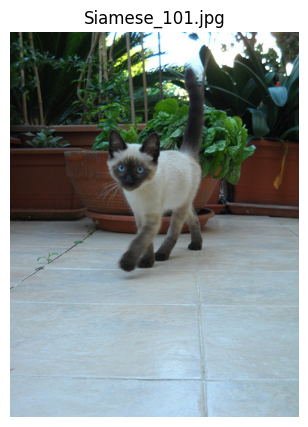

In [24]:
# Verificar que el archivo exista
if ruta_imagen.is_file():

	# Cargar la imagen con OpenCV (formato BGR)
	imagen_bgr = cv2.imread(str(ruta_imagen))

	if imagen_bgr is not None: # Si se logró abrir la imagen

		# Convertir de BGR a RGB
		imagen_rgb = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)

		# Mostrar información de la imagen
		print("Dimensiones:", imagen_rgb.shape)
		print("Tipo de dato:", imagen_rgb.dtype)
		print("Valores únicos:", np.unique(imagen_rgb))
		
		# Visualizar
		plt.figure(figsize=(7, 5))
		plt.imshow(imagen_rgb)
		plt.title(ruta_imagen.name)
		plt.axis("off")
		plt.show()

	else: # Si no se logró abrir la imagen
		print("OpenCV no pudo leer la imagen.")

else: # Si el archivo no existe
	print(f"No se encontró la imagen: {ruta_imagen.resolve()}")

Dimensiones: (500, 375)
Tipo de dato: uint8
Valores únicos: [1 2 3]


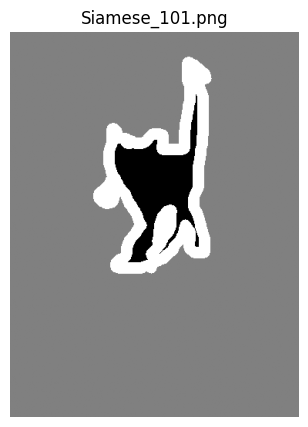

In [25]:
# Verificar que el archivo exista
if ruta_mascara.is_file():

	# Cargar la máscara conservando sus valores originales
	mascara = cv2.imread(str(ruta_mascara), cv2.IMREAD_UNCHANGED)

	if mascara is not None: # Si se logró abrir la imagen

		# Mostrar información de la máscara
		print("Dimensiones:", mascara.shape)
		print("Tipo de dato:", mascara.dtype)
		print("Valores únicos:", np.unique(mascara))

		# Visualizar
		plt.figure(figsize=(7, 5))
		plt.imshow(mascara, cmap="gray", vmin=1, vmax=3)
		plt.title(ruta_mascara.name)
		plt.axis("off")
		plt.show()

	else: # Si no se logró abrir la imagen
		print("OpenCV no pudo leer la máscara.")

else: # Si el archivo no existe
	print(f"No se encontró la máscara: {ruta_mascara.resolve()}")

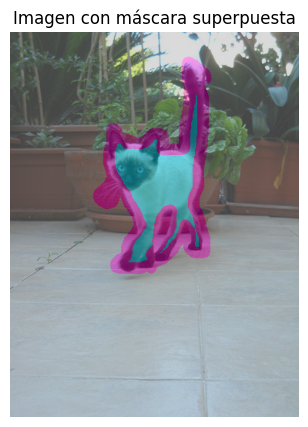

In [26]:
# Verificar que imagen y máscara tengan las mismas dimensiones
if imagen_rgb.shape[:2] == mascara.shape[:2]:

	# Crear una imagen RGB del mismo tamaño que la original
	mascara_color = np.zeros_like(imagen_rgb)

   # Asignar colores a las etiquetas
	mascara_color[mascara == 1] = (0, 229, 255)    # Animal: cian
	mascara_color[mascara == 2] = (163, 163, 163)  # Fondo: gris
	mascara_color[mascara == 3] = (255, 0, 204)    # Contorno: magenta

	# Definir transparencia
	alpha = 0.4

	# Combinar imagen original y máscara coloreada
	superposicion = cv2.addWeighted(
		imagen_rgb, 1 - alpha,
		mascara_color, alpha,
		0
	)

	# Visualizar
	plt.figure(figsize=(7, 5))
	plt.imshow(superposicion)
	plt.title("Imagen con máscara superpuesta")
	plt.axis("off")
	plt.show()

else:
	print("La imagen y la máscara tienen dimensiones diferentes.")

In [27]:
# Agregar bounding box de la cabeza de la estructura de la sección anterior
# Extraer las coordenadas del bounding box
xmin = int(raiz.findtext("object/bndbox/xmin"))
ymin = int(raiz.findtext("object/bndbox/ymin"))
xmax = int(raiz.findtext("object/bndbox/xmax"))
ymax = int(raiz.findtext("object/bndbox/ymax"))

# Obtener la clase del objeto
clase = raiz.findtext("object/name")

# Mostrar información
print("Clase:", clase)
print("Bounding box:", xmin, ymin, xmax, ymax)

Clase: cat
Bounding box: 126 128 194 206


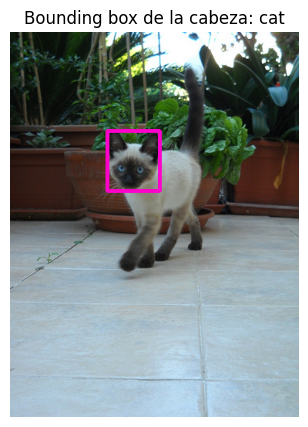

In [28]:
# Crear una copia de la imagen original
imagen_bbox = imagen_rgb.copy()

# Dibujar el bounding box
cv2.rectangle(
    imagen_bbox,
    (xmin, ymin),        # Esquina superior izquierda
    (xmax, ymax),        # Esquina inferior derecha
    color=(255, 0, 204), # Magenta (RGB)
    thickness=3          # Grosor del borde
)

# Visualizar
plt.figure(figsize=(7, 5))
plt.imshow(imagen_bbox)
plt.title(f"Bounding box de la cabeza: {clase}")
plt.axis("off")
plt.show()